# Floor 6 Zone 1/2/4/5 Baseline v3：15 分钟时间槽 + Operation-aware Baseline

本 notebook 建立 hybrid state-aware statistical baseline，用于检测 Floor 6 的 Zone 1、2、4、5 中多个 building log 变量的异常。

当前代码的核心逻辑是：

- 使用 `zone + day_type + fifteen_minute_slot + variable + baseline_state` 建立 baseline profile。
- AC 使用 `ac_state` 作为 `baseline_state`，并从稳定 baseline 中排除 `Transition`。
- 非 AC 变量使用 `baseline_state = "not_applicable"`。
- AC、light 和 lux 使用 empirical quantile 作为主候选规则。
- temperature、humidity 和 plug 使用 robust-z 作为主候选规则。
- OFF-like / near-zero 场景使用 zero-aware threshold。
- 最终异常点需要通过持续时间过滤，然后合并为 anomaly events 并计算 severity。

因此，本 notebook 的解释应以各 cell 实际输出的表格为准，不使用旧版本或手工写死的统计结果。


## 1. 导入依赖库

本步骤导入数据处理、数值计算和可视化所需的 Python 库。


In [30]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)
plt.style.use("default")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


def safe_print(*args) -> None:
    text = " ".join(str(arg) for arg in args)
    try:
        print(text)
    except UnicodeEncodeError:
        print(text.encode("ascii", errors="backslashreplace").decode("ascii"))


### 本步骤结果解释

这个 cell 只完成环境准备：导入 `pandas`、`numpy` 和 `matplotlib`，并设置表格显示宽度、中文字体和安全打印函数。它本身不产生分析结果，但它保证后续所有统计表、图表和中文说明都能稳定运行。

之所以需要在这里配置中文字体，是因为后续图表标题和坐标轴使用中文。如果不设置字体，保存出来的 PNG 图可能出现中文方框或缺字。`safe_print()` 则用于避免 Windows 控制台因为默认编码不支持中文而中断 notebook。


## 2. 参数配置

输入数据是上一份数据准备 notebook 生成的 baseline-ready 数据表。baseline 的输出目录与 EDA 输出目录分开保存，方便后续查看异常检测结果。

模型使用 6 个 15 分钟 rolling mean 字段作为异常检测变量。这样可以降低 1 分钟原始数据的短时噪声，同时仍然保留分钟级时间线。


In [31]:
NOTEBOOK_CWD = Path.cwd()
if not (NOTEBOOK_CWD / "outputs").exists() and (NOTEBOOK_CWD.parent / "outputs").exists():
    NOTEBOOK_CWD = NOTEBOOK_CWD.parent
INPUT_DIR = NOTEBOOK_CWD / "outputs" / "floor6_zone1245_2018_jul01_sep01_total_ac_eda"
INPUT_DATASET = INPUT_DIR / "floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz"

OUTPUT_DIR = NOTEBOOK_CWD / "outputs" / "floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware"
TABLE_DIR = OUTPUT_DIR / "baseline_tables"
FIGURE_DIR = OUTPUT_DIR / "baseline_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

ROLLING_VARIABLE_COLUMNS = [
    "total_AC_power_kw_rolling_mean_15min",
    "light_power_kw_rolling_mean_15min",
    "plug_power_kw_rolling_mean_15min",
    "temperature_c_rolling_mean_15min",
    "humidity_pct_rolling_mean_15min",
    "lux_rolling_mean_15min",
]

VARIABLE_LABELS = {
    "total_AC_power_kw_rolling_mean_15min": "total_AC_power_kw",
    "light_power_kw_rolling_mean_15min": "light_power_kw",
    "plug_power_kw_rolling_mean_15min": "plug_power_kw",
    "temperature_c_rolling_mean_15min": "temperature_c",
    "humidity_pct_rolling_mean_15min": "humidity_pct",
    "lux_rolling_mean_15min": "lux",
}

WAS_MISSING_COLUMNS = {
    "total_AC_power_kw": "total_AC_power_kw_was_missing",
    "light_power_kw": "light_power_kw_was_missing",
    "plug_power_kw": "plug_power_kw_was_missing",
    "temperature_c": "temperature_c_was_missing",
    "humidity_pct": "humidity_pct_was_missing",
    "lux": "lux_was_missing",
}

ROBUST_Z_THRESHOLD = 3.5
MIN_PERSISTENCE_MINUTES = 15
MAD_EPSILON = 1e-9

# Prevent tiny non-zero MAD values from exploding robust-z scores.
# Values are in the same units as each source variable.
ROBUST_MAD_FLOORS = {
    "total_AC_power_kw": 0.25,
    "light_power_kw": 0.05,
    "plug_power_kw": 0.02,
    "temperature_c": 0.10,
    "humidity_pct": 0.50,
    "lux": 1.00,
}

PERIOD_ROBUST_Z_THRESHOLDS = {
    "core_work": 4.0,
    "ramp_up": 4.0,
    "ramp_down": 4.0,
    "evening_off": 3.5,
    "night_off": 3.0,
    "weekend": 3.0,
}

ENERGY_LIKE_VARIABLES = {"total_AC_power_kw", "light_power_kw", "plug_power_kw", "lux"}
ENVIRONMENT_VARIABLES = {"temperature_c", "humidity_pct"}
NON_WORK_PERIODS = {"evening_off", "night_off", "weekend"}
WORK_PERIODS = {"core_work", "ramp_up", "ramp_down"}

ZERO_AWARE_VARIABLES = {"total_AC_power_kw", "light_power_kw", "lux"}
SMALL_MIN_THRESHOLDS = {
    "total_AC_power_kw": 1.0,
    "light_power_kw": 0.2,
    "plug_power_kw": 0.2,
    "lux": 5.0,
}

# AC, light, and lux often have mixed operating regimes.
# Their candidate logic is therefore based on empirical quantiles,
# while plug, temperature, and humidity keep robust-z as the main rule.
QUANTILE_HIGH_VARIABLES = {"total_AC_power_kw", "light_power_kw", "lux"}
QUANTILE_LOW_VARIABLES = {"light_power_kw", "lux"}
ROBUST_RULE_VARIABLES = (
    set(VARIABLE_LABELS.values())
    - QUANTILE_HIGH_VARIABLES
    - QUANTILE_LOW_VARIABLES
)

QUANTILE_HIGH_MIN_EXCESS = {
    "total_AC_power_kw": 1.0,
    "light_power_kw": 0.2,
    "lux": 5.0,
}

QUANTILE_LOW_MIN_DROP = {
    "light_power_kw": 0.2,
    "lux": 5.0,
}

QUANTILE_SCORE_EPSILON = 1e-9

BASELINE_GROUP_COLUMNS = ["zone", "day_type", "fifteen_minute_slot", "variable", "baseline_state"]

safe_print("输入数据集:", INPUT_DATASET)
safe_print("输出目录:", OUTPUT_DIR)


输入数据集: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz
输出目录: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware


### 本步骤结果解释

这个 cell 定义 baseline 的输入文件、输出目录、检测变量、变量分类和阈值配置。输入数据来自数据准备 notebook 生成的 baseline-ready 数据表。

当前代码使用 `ROLLING_VARIABLE_COLUMNS` 中列出的 rolling mean 字段作为检测对象，并通过 `VARIABLE_LABELS` 映射为最终变量名。是否存在缺失值由 `WAS_MISSING_COLUMNS` 指定的字段保留，用于后续解释异常点是否落在曾经被填补的位置。

阈值设置分为几类：`ROBUST_MAD_FLOORS` 用于避免 tiny MAD 放大 robust-z；`PERIOD_ROBUST_Z_THRESHOLDS` 用于不同运行时段的 robust-z 判定；`ZERO_AWARE_VARIABLES` 和 `SMALL_MIN_THRESHOLDS` 用于 near-zero 场景；`QUANTILE_HIGH_VARIABLES`、`QUANTILE_LOW_VARIABLES` 及其最小差值用于 AC、light 和 lux 的分位数规则。


## 3. 读取 Baseline-Ready 数据集

本步骤读取已经完成清洗、缺失值填补和基础特征工程的数据集，并检查 rolling 变量和缺失标记字段是否存在。


In [32]:
if not INPUT_DATASET.exists():
    raise FileNotFoundError(f"Missing input dataset: {INPUT_DATASET}")

# Validate the input contract from the data-preparation notebook before accessing columns.
required_columns = set(
    [
        "timestamp", "year", "floor", "zone", "month", "date", "hour", "minute",
        "day_of_week", "day_name", "day_type", "is_weekend", "is_work_hour", "minute_of_day",
        "ac_state",
    ]
    + ROLLING_VARIABLE_COLUMNS
    + list(WAS_MISSING_COLUMNS.values())
)

df = pd.read_csv(INPUT_DATASET, parse_dates=["timestamp"])
missing_required = sorted(required_columns.difference(df.columns))
if missing_required:
    raise ValueError(f"Input dataset is missing required columns: {missing_required}")

df["date"] = pd.to_datetime(df["date"]).dt.date

for bool_col in ["is_weekend", "is_work_hour"]:
    if df[bool_col].dtype == "object":
        df[bool_col] = df[bool_col].astype(str).str.strip().str.lower().eq("true")

slot_minutes = (df["minute_of_day"] // 15 * 15).astype(int)
df["fifteen_minute_slot"] = slot_minutes
df["fifteen_minute_slot_label"] = (
    (slot_minutes // 60).astype(str).str.zfill(2)
    + ":"
    + (slot_minutes % 60).astype(str).str.zfill(2)
)

load_summary = pd.DataFrame([{
    "rows": len(df),
    "columns": len(df.columns),
    "min_timestamp": df["timestamp"].min(),
    "max_timestamp": df["timestamp"].max(),
    "zones": ",".join(map(str, sorted(df["zone"].unique()))),
    "missing_values": int(df.isna().sum().sum()),
}])
load_summary.to_csv(TABLE_DIR / "01_load_summary.csv", index=False)

display(load_summary)
display(df.head())


,rows,columns,min_timestamp,max_timestamp,zones,missing_values
0,362880,40,2018-07-01,2018-09-01 23:59:00,"1,2,4,5",339269


,timestamp,year,floor,zone,source_file,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,ac_meter_count,has_ac_meter,month,date,hour,minute,day_of_week,day_name,is_weekend,day_type,is_work_hour,minute_of_day,total_AC_power_kw_was_missing,light_power_kw_was_missing,plug_power_kw_was_missing,temperature_c_was_missing,humidity_pct_was_missing,lux_was_missing,total_AC_power_kw_rolling_mean_15min,light_power_kw_rolling_mean_15min,plug_power_kw_rolling_mean_15min,temperature_c_rolling_mean_15min,humidity_pct_rolling_mean_15min,lux_rolling_mean_15min,ac_state,transition_type,ac_off_threshold_kw,fifteen_minute_slot,fifteen_minute_slot_label
0,2018-07-01 00:00:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.19,0.0,1,True,7,2018-07-01,0,0,6,Sunday,True,Weekend,False,0,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,OFF,NaN,0.5,0,00:00
1,2018-07-01 00:01:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True,7,2018-07-01,0,1,6,Sunday,True,Weekend,False,1,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,OFF,NaN,0.5,0,00:00
2,2018-07-01 00:02:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True,7,2018-07-01,0,2,6,Sunday,True,Weekend,False,2,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,OFF,NaN,0.5,0,00:00
3,2018-07-01 00:03:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True,7,2018-07-01,0,3,6,Sunday,True,Weekend,False,3,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,OFF,NaN,0.5,0,00:00
4,2018-07-01 00:04:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True,7,2018-07-01,0,4,6,Sunday,True,Weekend,False,4,False,False,False,False,False,False,0.0,0.0,0.29,27.566,72.178,0.0,OFF,NaN,0.5,0,00:00


### 本步骤结果解释

这个 cell 读取 baseline-ready 数据，并用 `required_columns` 检查后续代码依赖的字段是否完整。具体行数、列数、时间范围、zone 列表和缺失值数量以 `load_summary` 的当前输出为准。

这个检查很重要，因为后续 baseline profile、候选点判定、持续时间过滤和事件合并都依赖完整的时间序列和必要字段。如果输入数据缺少 rolling 变量、缺失标记或 AC 状态字段，代码会在这里直接报错。


## 4. 定义运行时段 Operating Period

这个步骤根据 `is_weekend` 和 `hour` 生成 `operating_period`，用于后续阈值选择、异常解释和汇总。

运行时段划分由当前代码中的 `assign_operating_period` 决定：

- `weekend`：周六、周日全天
- `night_off`：工作日 00:00-06:59
- `ramp_up`：工作日 07:00-07:59
- `core_work`：工作日 08:00-16:59
- `ramp_down`：工作日 17:00-18:59
- `evening_off`：工作日 19:00-23:59

baseline profile 的分组不直接使用 `operating_period`，而是使用更细的 `fifteen_minute_slot`，并额外包含 `baseline_state`。`operating_period` 主要用于动态阈值、持续时间规则、zero-aware 场景和结果汇总。


In [33]:
def assign_operating_period(frame: pd.DataFrame) -> pd.Series:
    conditions = [
        frame["is_weekend"],
        frame["hour"].between(0, 6),
        frame["hour"].eq(7),
        frame["hour"].between(8, 16),
        frame["hour"].between(17, 18),
        frame["hour"].between(19, 23),
    ]
    labels = [
        "weekend",
        "night_off",
        "ramp_up",
        "core_work",
        "ramp_down",
        "evening_off",
    ]
    return pd.Series(np.select(conditions, labels, default="unknown"), index=frame.index)


df["operating_period"] = assign_operating_period(df)
operating_period_summary = (
    df.groupby(["day_type", "operating_period"])
    .agg(rows=("timestamp", "size"), min_hour=("hour", "min"), max_hour=("hour", "max"))
    .reset_index()
    .sort_values(["day_type", "min_hour", "operating_period"])
)
operating_period_summary.to_csv(TABLE_DIR / "02_operating_period_summary.csv", index=False)

display(operating_period_summary)


,day_type,operating_period,rows,min_hour,max_hour
2,Weekday,night_off,75600,0,6
4,Weekday,ramp_up,10800,7,7
0,Weekday,core_work,97200,8,16
3,Weekday,ramp_down,21600,17,18
1,Weekday,evening_off,54000,19,23
5,Weekend,weekend,103680,0,23


### 本步骤结果解释

这个 cell 根据当前代码规则把每条记录划分到一个 `operating_period`。各运行时段的样本数量以 `operating_period_summary` 的当前输出为准。

这个字段不替代 15 分钟 baseline 分组，而是为后续逻辑提供运行背景：robust-z 阈值会按运行时段选择；非工作时段会触发部分 zero-aware 逻辑；最终事件表和汇总表也会用它解释异常发生在哪类运行阶段。


## 5. 宽表转换为长表

原始 baseline-ready 表中，每一行同时包含多个变量。为了对所有变量分别建立 baseline，这里将宽表转换为长表。

转换后，每一行代表一个时间点、一个 zone、一个变量的观测值。这样每个变量都可以拥有自己的 baseline、异常分数和异常标记。


In [34]:
long_parts = []
id_columns = [
    "timestamp", "year", "floor", "zone", "month", "date", "hour", "minute",
    "day_of_week", "day_name", "day_type", "is_weekend", "is_work_hour",
    "minute_of_day", "fifteen_minute_slot", "fifteen_minute_slot_label", "operating_period", "ac_state",
]

for source_column in ROLLING_VARIABLE_COLUMNS:
    variable = VARIABLE_LABELS[source_column]
    part = df[id_columns].copy()
    part["variable"] = variable
    part["source_column"] = source_column
    part["actual_value"] = df[source_column].astype(float)
    part["was_missing"] = df[WAS_MISSING_COLUMNS[variable]].astype(bool)
    long_parts.append(part)

baseline_long = pd.concat(long_parts, ignore_index=True)
baseline_long = baseline_long.sort_values(["zone", "variable", "timestamp"]).reset_index(drop=True)
baseline_long.head(1000).to_csv(TABLE_DIR / "03_baseline_input_long_preview.csv", index=False)

long_summary = baseline_long.groupby("variable").agg(
    rows=("actual_value", "size"),
    min_value=("actual_value", "min"),
    median_value=("actual_value", "median"),
    max_value=("actual_value", "max"),
    was_missing_pct=("was_missing", lambda s: s.mean() * 100),
).round(4).reset_index()
long_summary.to_csv(TABLE_DIR / "04_long_variable_summary.csv", index=False)

display(long_summary)
display(baseline_long.head())


,variable,rows,min_value,median_value,max_value,was_missing_pct
0,humidity_pct,362880,46.9833,64.1220,75.3407,4.5580
1,light_power_kw,362880,0.0000,0.0100,8.1927,0.7727
2,lux,362880,0.0000,0.2000,72.2000,4.5580
3,plug_power_kw,362880,0.0067,0.1713,2.8013,0.5440
4,temperature_c,362880,19.6800,27.2530,32.2616,4.5580
5,total_AC_power_kw,362880,0.0000,0.0000,36.1247,0.3492


,timestamp,year,floor,zone,month,date,hour,minute,day_of_week,day_name,day_type,is_weekend,is_work_hour,minute_of_day,fifteen_minute_slot,fifteen_minute_slot_label,operating_period,ac_state,variable,source_column,actual_value,was_missing
0,2018-07-01 00:00:00,2018,6,1,7,2018-07-01,0,0,6,Sunday,Weekend,True,False,0,0,00:00,weekend,OFF,humidity_pct,humidity_pct_rolling_mean_15min,NaN,False
1,2018-07-01 00:01:00,2018,6,1,7,2018-07-01,0,1,6,Sunday,Weekend,True,False,1,0,00:00,weekend,OFF,humidity_pct,humidity_pct_rolling_mean_15min,NaN,False
2,2018-07-01 00:02:00,2018,6,1,7,2018-07-01,0,2,6,Sunday,Weekend,True,False,2,0,00:00,weekend,OFF,humidity_pct,humidity_pct_rolling_mean_15min,NaN,False
3,2018-07-01 00:03:00,2018,6,1,7,2018-07-01,0,3,6,Sunday,Weekend,True,False,3,0,00:00,weekend,OFF,humidity_pct,humidity_pct_rolling_mean_15min,NaN,False
4,2018-07-01 00:04:00,2018,6,1,7,2018-07-01,0,4,6,Sunday,Weekend,True,False,4,0,00:00,weekend,OFF,humidity_pct,humidity_pct_rolling_mean_15min,72.178,False


### 本步骤结果解释

这个 cell 把 wide table 转换成长表。当前长表行数、变量数量和缺失标记统计以 `long_summary` 和 `baseline_long.head()` 的输出为准。

长表结构让每个变量都能独立匹配自己的 baseline profile，并保留同一时间点的 `zone`、`day_type`、`fifteen_minute_slot`、`operating_period`、`ac_state` 和 `was_missing` 等上下文字段。后续所有 scoring 和 event merge 都基于这个长表。


## 6. 建立 State-aware Baseline Profile

统计 baseline 按当前代码中的 `BASELINE_GROUP_COLUMNS` 分组：

`zone + day_type + fifteen_minute_slot + variable + baseline_state`

其中 AC 的 `baseline_state` 来自 `ac_state`，非 AC 变量使用 `not_applicable`。AC 的 `Transition` 记录会从 stable baseline profile 中排除，避免过渡状态污染 OFF 或 ON_stable 的正常参考值。

每个分组会计算：

- `total_rows`、`valid_count`
- `baseline_mean`、`baseline_std`
- `baseline_median`、`baseline_mad`
- `p01`、`p05`、`q1`、`q3`、`p95`、`p99`
- `min_value`、`max_value`、`zero_pct`
- `iqr`、`scaled_mad`、`mad_is_zero`

这些统计量分别支持 robust-z、quantile candidate、zero-aware threshold 和结果解释。


In [35]:
def median_absolute_deviation(series: pd.Series) -> float:

    values = series.dropna().to_numpy()

    if len(values) == 0:
        return np.nan

    median = np.median(values)

    return float(
        np.median(np.abs(values - median))
    )


# ============================================================
# Add baseline state
# ============================================================

baseline_long = baseline_long.copy()

baseline_long["baseline_state"] = "not_applicable"

ac_mask = baseline_long["variable"].eq(
    "total_AC_power_kw"
)

baseline_long.loc[
    ac_mask,
    "baseline_state"
] = baseline_long.loc[
    ac_mask,
    "ac_state"
]


# ============================================================
# Exclude AC transition periods from baseline profile
# ============================================================

baseline_for_profile = baseline_long[
    ~(
        baseline_long["variable"].eq("total_AC_power_kw")
        & baseline_long["baseline_state"].eq("Transition")
    )
].copy()


baseline_profile = (
    baseline_for_profile
    .groupby(BASELINE_GROUP_COLUMNS)["actual_value"]
    .agg(
        total_rows="size",
        valid_count="count",

        baseline_mean="mean",
        baseline_std="std",
        baseline_median="median",
        baseline_mad=median_absolute_deviation,

        p01=lambda s: s.quantile(0.01),
        p05=lambda s: s.quantile(0.05),
        q1=lambda s: s.quantile(0.25),
        q3=lambda s: s.quantile(0.75),
        p95=lambda s: s.quantile(0.95),
        p99=lambda s: s.quantile(0.99),

        min_value="min",
        max_value="max",

        zero_pct=lambda s: s.eq(0).mean() * 100,
    )
    .reset_index()
)


# ============================================================
# Additional statistics
# ============================================================

baseline_profile["iqr"] = (
    baseline_profile["q3"]
    - baseline_profile["q1"]
)

baseline_profile["scaled_mad"] = (
    1.4826
    * baseline_profile["baseline_mad"]
)

baseline_profile["mad_is_zero"] = (
    baseline_profile["baseline_mad"].abs()
    <= MAD_EPSILON
)


# ============================================================
# Save baseline profile
# ============================================================

baseline_profile.to_csv(
    TABLE_DIR
    / "05_baseline_profile_by_zone_day_15min_slot_variable_state.csv",
    index=False
)


# ============================================================
# Summary
# ============================================================

profile_summary = (
    baseline_profile
    .groupby("variable")
    .agg(
        groups=("valid_count", "size"),

        min_group_size=("valid_count", "min"),

        median_group_size=("valid_count", "median"),

        zero_median_group_pct=(
            "baseline_median",
            lambda s: s.eq(0).mean() * 100
        ),

        zero_mad_group_pct=(
            "mad_is_zero",
            lambda s: s.mean() * 100
        ),

        median_mad=(
            "baseline_mad",
            "median"
        ),

        median_scaled_mad=(
            "scaled_mad",
            "median"
        ),
    )
    .round(4)
    .reset_index()
)


profile_summary.to_csv(
    TABLE_DIR
    / "06_baseline_profile_summary.csv",
    index=False
)

display(profile_summary)

display(baseline_profile.head())

,variable,groups,min_group_size,median_group_size,zero_median_group_pct,zero_mad_group_pct,median_mad,median_scaled_mad
0,humidity_pct,768,266,472.5,0.0000,0.0000,2.1771,3.2277
1,light_power_kw,768,266,472.5,42.9688,54.1667,0.0000,0.0000
2,lux,768,266,472.5,51.4323,51.4323,0.0000,0.0000
3,plug_power_kw,768,266,472.5,0.0000,0.0000,0.0390,0.0578
4,temperature_c,768,266,472.5,0.0000,0.0000,0.4877,0.7230
5,total_AC_power_kw,923,2,270.0,82.9902,83.6403,0.0000,0.0000


,zone,day_type,fifteen_minute_slot,variable,baseline_state,total_rows,valid_count,baseline_mean,baseline_std,baseline_median,baseline_mad,p01,p05,q1,q3,p95,p99,min_value,max_value,zero_pct,iqr,scaled_mad,mad_is_zero
0,1,Weekday,0,humidity_pct,not_applicable,675,675,62.721385,4.323057,62.344,3.096667,56.584787,56.921267,58.662000,64.951429,70.586133,73.145853,56.546000,73.428000,0.0,6.289429,4.591118,False
1,1,Weekday,0,light_power_kw,not_applicable,675,675,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.0,0.000000,0.000000,True
2,1,Weekday,0,lux,not_applicable,675,675,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.0,0.000000,0.000000,True
3,1,Weekday,0,plug_power_kw,not_applicable,675,675,0.231207,0.046641,0.232,0.032000,0.116000,0.148467,0.198667,0.263333,0.298867,0.332347,0.103333,0.363333,0.0,0.064667,0.047443,False
4,1,Weekday,0,temperature_c,not_applicable,675,675,27.706990,0.860443,27.492,0.561333,26.647333,26.733133,26.983333,28.379333,29.300400,30.723467,26.643333,30.753333,0.0,1.396000,0.832233,False


### 本步骤结果解释

这个 cell 建立 state-aware baseline profile。AC 会按 `zone + day_type + fifteen_minute_slot + variable + baseline_state` 分组，非 AC 变量的 `baseline_state` 为 `not_applicable`。这样 AC 的 OFF、ON_stable 和 Transition 不会混在同一个 baseline 中；其中 Transition 会从 stable baseline profile 中排除。

profile 同时保存 median、MAD、p01、p05、q1、q3、p95、p99 和 zero_pct。`p01/p05/q1` 用于照明和 lux 的低值异常判断，`p95/p99` 用于 AC、照明和 lux 的高值异常判断，MAD/robust-z 则保留给温湿度和 plug 这类更连续的变量。

这个版本的重点不是追求所有变量都用同一种统计量，而是让 baseline 与设备运行状态一致，避免 AC 在 ON 稳态下仍被 OFF-dominated 分组拉低基线。


## 7. 计算与 Baseline 的偏差、Robust Score 和 Quantile Score

每条长表记录会按照 `BASELINE_GROUP_COLUMNS` 匹配到自己的 state-aware baseline profile。代码随后计算：

- `deviation` 和 `abs_deviation`
- `rolling_value_available`
- `raw_robust_z_score`
- 使用 `ROBUST_MAD_FLOORS` 后的 `robust_z_score`
- `uses_mad_floor`
- zero-aware threshold 相关字段
- p95/p99 与 q1/p05 相关的 quantile ranking score
- `unexpected_ac_on_non_work`

因此，本步骤不仅生成 robust-z，也生成分位数规则和 zero-aware 规则所需的全部诊断字段。


In [36]:
# ============================================================
# Prepare scoring source
# ============================================================

# Transition periods are excluded from the stable AC baseline.
# Therefore they are also excluded from robust-z scoring here.
#
# They can still be retained separately for transition analysis.
score_source = baseline_long[
    ~(
        baseline_long["variable"].eq("total_AC_power_kw")
        & baseline_long["baseline_state"].eq("Transition")
    )
].copy()


# ============================================================
# Match each observation to its baseline profile
# ============================================================

scores = score_source.merge(
    baseline_profile,
    on=BASELINE_GROUP_COLUMNS,
    how="left",
    validate="many_to_one"
)


# ============================================================
# Validate baseline matching
# ============================================================

unmatched = scores["baseline_median"].isna()

if unmatched.any():

    unmatched_summary = (
        scores.loc[
            unmatched,
            BASELINE_GROUP_COLUMNS
        ]
        .drop_duplicates()
    )

    display(unmatched_summary)

    raise ValueError(
        f"{unmatched.sum()} records could not be matched "
        f"to a baseline profile."
    )


# ============================================================
# Deviation from baseline median
# ============================================================

scores["deviation"] = (
    scores["actual_value"]
    - scores["baseline_median"]
)

scores["abs_deviation"] = (
    scores["deviation"].abs()
)

scores["rolling_value_available"] = scores["actual_value"].notna()


# ============================================================
# Robust Z-score
#
# 0.6745 / MAD
# is approximately equivalent to:
#
# deviation / (1.4826 * MAD)
# ============================================================

scores["robust_mad_floor"] = (
    scores["variable"]
    .map(ROBUST_MAD_FLOORS)
    .fillna(0.0)
)

scores["effective_baseline_mad"] = np.maximum(
    scores["baseline_mad"].abs(),
    scores["robust_mad_floor"],
)

scores["uses_mad_floor"] = (
    scores["baseline_mad"].abs()
    < scores["robust_mad_floor"]
)

scores["raw_robust_z_score"] = np.where(
    scores["baseline_mad"].abs() > MAD_EPSILON,

    0.6745
    * scores["deviation"]
    / scores["baseline_mad"],

    np.nan,
)

scores["robust_z_score"] = np.where(
    scores["effective_baseline_mad"].abs() > MAD_EPSILON,

    0.6745
    * scores["deviation"]
    / scores["effective_baseline_mad"],

    np.nan,
)

scores["abs_robust_z_score"] = (
    scores["robust_z_score"].abs()
)


# ============================================================
# Variable classifications
# ============================================================

scores["small_min_threshold"] = (
    scores["variable"]
    .map(SMALL_MIN_THRESHOLDS)
    .fillna(np.nan)
)

scores["is_energy_like_variable"] = (
    scores["variable"]
    .isin(ENERGY_LIKE_VARIABLES)
)

scores["is_environment_variable"] = (
    scores["variable"]
    .isin(ENVIRONMENT_VARIABLES)
)

scores["is_non_work_period"] = (
    scores["operating_period"]
    .isin(NON_WORK_PERIODS)
)


# ============================================================
# Operating-period-specific Robust-Z threshold
# ============================================================

scores["period_robust_z_threshold"] = (
    scores["operating_period"]
    .map(PERIOD_ROBUST_Z_THRESHOLDS)
    .fillna(ROBUST_Z_THRESHOLD)
)


# ============================================================
# Zero-aware reference
# ============================================================

scores["zero_aware_reference"] = np.where(
    scores["is_energy_like_variable"]
    & scores["is_non_work_period"],

    scores["p99"],

    scores["p95"],
)


scores["zero_aware_threshold"] = np.maximum(
    scores["zero_aware_reference"],
    scores["small_min_threshold"]
    .fillna(-np.inf)
)


# ============================================================
# Zero-aware rule
# ============================================================

# AC OFF state should use the zero-aware rule rather than
# relying on MAD when the baseline is near zero.

ac_off_mask = (
    scores["variable"].eq("total_AC_power_kw")
    & scores["baseline_state"].eq("OFF")
)

near_zero_baseline_mask = (
    scores["variable"].isin(ZERO_AWARE_VARIABLES)
    & scores["baseline_median"].abs().le(MAD_EPSILON)
    & scores["baseline_mad"].abs().le(MAD_EPSILON)
)

non_work_energy_mask = (
    scores["is_energy_like_variable"]
    & scores["is_non_work_period"]
)

scores["uses_zero_aware_rule"] = (
    ac_off_mask
    | near_zero_baseline_mask
    | non_work_energy_mask
)

scores.loc[
    ~scores["uses_zero_aware_rule"],
    ["zero_aware_reference", "zero_aware_threshold"],
] = np.nan


# ============================================================
# Additional reference indicators
# ============================================================

scores["exceeds_p99"] = (
    scores["actual_value"] > scores["p99"]
)

scores["below_p05"] = (
    scores["actual_value"] < scores["p05"]
)


# ============================================================
# Quantile-based references
# ============================================================

scores["high_quantile_min_excess"] = (
    scores["variable"]
    .map(QUANTILE_HIGH_MIN_EXCESS)
    .fillna(0.0)
)

scores["low_quantile_min_drop"] = (
    scores["variable"]
    .map(QUANTILE_LOW_MIN_DROP)
    .fillna(0.0)
)

scores["high_quantile_reference"] = scores["p95"]
scores["high_extreme_reference"] = scores["p99"]
scores["low_quantile_reference"] = scores["q1"]
scores["low_extreme_reference"] = scores["p05"]

scores["high_quantile_band"] = np.maximum(
    (scores["high_extreme_reference"] - scores["high_quantile_reference"]).abs(),
    scores["high_quantile_min_excess"],
)

scores["low_quantile_band"] = np.maximum(
    (scores["low_quantile_reference"] - scores["low_extreme_reference"]).abs(),
    scores["low_quantile_min_drop"],
)

scores["high_quantile_excess_unit"] = np.where(
    scores["high_quantile_band"].gt(QUANTILE_SCORE_EPSILON),
    (
        scores["actual_value"]
        - scores["high_quantile_reference"]
    )
    / scores["high_quantile_band"],
    np.nan,
)

scores["low_quantile_drop_unit"] = np.where(
    scores["low_quantile_band"].gt(QUANTILE_SCORE_EPSILON),
    (
        scores["low_quantile_reference"]
        - scores["actual_value"]
    )
    / scores["low_quantile_band"],
    np.nan,
)

scores["high_quantile_score"] = np.where(
    scores["high_quantile_excess_unit"].gt(0),
    4 + 2 * scores["high_quantile_excess_unit"],
    np.nan,
)

scores["low_quantile_score"] = np.where(
    scores["low_quantile_drop_unit"].gt(0),
    4 + 2 * scores["low_quantile_drop_unit"],
    np.nan,
)

scores["quantile_score_for_ranking"] = (
    scores[["high_quantile_score", "low_quantile_score"]]
    .max(axis=1)
)


# ============================================================
# Optional schedule-state mismatch indicator
# ============================================================

# This is useful because an AC may be statistically normal
# for an ON state, but still unusual if it is ON during
# night/weekend periods.

scores["unexpected_ac_on_non_work"] = (
    scores["variable"].eq("total_AC_power_kw")
    & scores["baseline_state"].eq("ON_stable")
    & scores["is_non_work_period"]
)


# ============================================================
# Score summary
# ============================================================

score_summary = (
    scores
    .groupby("variable")
    .agg(
        rows=(
            "actual_value",
            "size"
        ),

        robust_score_available_pct=(
            "robust_z_score",
            lambda s: s.notna().mean() * 100
        ),

        zero_aware_rows_pct=(
            "uses_zero_aware_rule",
            lambda s: s.mean() * 100
        ),

        median_abs_deviation_from_baseline=(
            "abs_deviation",
            "median"
        ),

        p95_abs_deviation_from_baseline=(
            "abs_deviation",
            lambda s: s.quantile(0.95)
        ),
    )
    .round(4)
    .reset_index()
)


score_summary.to_csv(
    TABLE_DIR / "07_score_availability_summary.csv",
    index=False
)

display(score_summary)

display(scores.head())

,variable,rows,robust_score_available_pct,zero_aware_rows_pct,median_abs_deviation_from_baseline,p95_abs_deviation_from_baseline
0,humidity_pct,362880,99.9956,0.0000,2.0630,7.7010
1,light_power_kw,362880,99.9956,64.2857,0.0193,2.1467
2,lux,362880,99.9956,64.8438,0.1467,32.4000
3,plug_power_kw,362880,99.9956,64.2857,0.0387,0.3093
4,temperature_c,362880,99.9956,0.0000,0.4080,1.7760
5,total_AC_power_kw,339173,99.9953,80.6718,0.0000,4.9171


,timestamp,year,floor,zone,month,date,hour,minute,day_of_week,day_name,day_type,is_weekend,is_work_hour,minute_of_day,fifteen_minute_slot,fifteen_minute_slot_label,operating_period,ac_state,variable,source_column,actual_value,was_missing,baseline_state,total_rows,valid_count,baseline_mean,baseline_std,baseline_median,baseline_mad,p01,p05,q1,q3,p95,p99,min_value,max_value,zero_pct,iqr,scaled_mad,mad_is_zero,deviation,abs_deviation,rolling_value_available,robust_mad_floor,effective_baseline_mad,uses_mad_floor,raw_robust_z_score,robust_z_score,abs_robust_z_score,small_min_threshold,is_energy_like_variable,is_environment_variable,is_non_work_period,period_robust_z_threshold,zero_aware_reference,zero_aware_threshold,uses_zero_aware_rule,exceeds_p99,below_p05,high_quantile_min_excess,low_quantile_min_drop,high_quantile_reference,high_extreme_reference,low_quantile_reference,low_extreme_reference,high_quantile_band,low_quantile_band,high_quantile_excess_unit,low_quantile_drop_unit,high_quantile_score,low_quantile_score,quantile_score_for_ranking,unexpected_ac_on_non_work
0,2018-07-01 00:00:00,2018,6,1,7,2018-07-01,0,0,6,Sunday,Weekend,True,False,0,0,00:00,weekend,OFF,humidity_pct,humidity_pct_rolling_mean_15min,NaN,False,not_applicable,270,266,64.141562,4.335542,64.126667,2.514667,55.722133,55.791167,61.5385,66.637833,70.278333,72.168875,55.708,72.178,0.0,5.099333,3.728245,False,NaN,NaN,False,0.5,2.514667,False,NaN,NaN,NaN,NaN,False,True,True,3.0,NaN,NaN,False,False,False,0.0,0.0,70.278333,72.168875,61.5385,55.791167,1.890542,5.747333,NaN,NaN,NaN,NaN,NaN,False
1,2018-07-01 00:01:00,2018,6,1,7,2018-07-01,0,1,6,Sunday,Weekend,True,False,1,0,00:00,weekend,OFF,humidity_pct,humidity_pct_rolling_mean_15min,NaN,False,not_applicable,270,266,64.141562,4.335542,64.126667,2.514667,55.722133,55.791167,61.5385,66.637833,70.278333,72.168875,55.708,72.178,0.0,5.099333,3.728245,False,NaN,NaN,False,0.5,2.514667,False,NaN,NaN,NaN,NaN,False,True,True,3.0,NaN,NaN,False,False,False,0.0,0.0,70.278333,72.168875,61.5385,55.791167,1.890542,5.747333,NaN,NaN,NaN,NaN,NaN,False
2,2018-07-01 00:02:00,2018,6,1,7,2018-07-01,0,2,6,Sunday,Weekend,True,False,2,0,00:00,weekend,OFF,humidity_pct,humidity_pct_rolling_mean_15min,NaN,False,not_applicable,270,266,64.141562,4.335542,64.126667,2.514667,55.722133,55.791167,61.5385,66.637833,70.278333,72.168875,55.708,72.178,0.0,5.099333,3.728245,False,NaN,NaN,False,0.5,2.514667,False,NaN,NaN,NaN,NaN,False,True,True,3.0,NaN,NaN,False,False,False,0.0,0.0,70.278333,72.168875,61.5385,55.791167,1.890542,5.747333,NaN,NaN,NaN,NaN,NaN,False
3,2018-07-01 00:03:00,2018,6,1,7,2018-07-01,0,3,6,Sunday,Weekend,True,False,3,0,00:00,weekend,OFF,humidity_pct,humidity_pct_rolling_mean_15min,NaN,False,not_applicable,270,266,64.141562,4.335542,64.126667,2.514667,55.722133,55.791167,61.5385,66.637833,70.278333,72.168875,55.708,72.178,0.0,5.099333,3.728245,False,NaN,NaN,False,0.5,2.514667,False,NaN,NaN,NaN,NaN,False,True,True,3.0,NaN,NaN,False,False,False,0.0,0.0,70.278333,72.168875,61.5385,55.791167,1.890542,5.747333,NaN,NaN,NaN,NaN,NaN,False
4,2018-07-01 00:04:00,2018,6,1,7,2018-07-01,0,4,6,Sunday,Weekend,True,False,4,0,00:00,weekend,OFF,humidity_pct,humidity_pct_rolling_mean_15min,72.178,False,not_applicable,270,266,64.141562,4.335542,64.126667,2.514667,55.722133,55.791167,61.5385,66.637833,70.278333,72.168875,55.708,72.178,0.0,5.099333,3.728245,False,8.051333,8.051333,True,0.5,2.514667,False,2.15958,2.15958,2.15958,NaN,False,True,True,3.0,NaN,NaN,False,True,False,0.0,0.0,70.278333,72.168875,61.5385,55.791167,1.890542,5.747333,1.004827,-1.851206,6.009653,NaN,6.009653,False


### 本步骤结果解释

这个 cell 将每条长表记录匹配到自己的 state-aware baseline profile，并计算相对 baseline median 的偏差、MAD floor 后的 robust z-score，以及分位数 score。

robust z-score 现在主要作为连续变量的判定依据和所有变量的诊断信息。对于 AC、light 和 lux，候选点主规则改为 empirical quantile：高值看是否超过 p95/p99 区间，低照明和低 lux 看是否低于工作时段的 q1/p05 区间。

当变量处在 OFF-like 或非工作时段的 near-zero baseline 中，仍然使用 zero-aware threshold，避免 MAD 为 0 或接近 0 时造成不稳定评分。


## 8. 应用 Hybrid 异常候选规则

当前代码使用多规则候选点判定：

1. `robust_candidate`：只用于 `ROBUST_RULE_VARIABLES`，也就是 temperature、humidity 和 plug 这类连续变量。
2. `zero_aware_candidate`：用于 OFF-like、near-zero 或非工作时段能源场景，只判断异常高值。
3. `high_quantile_candidate`：用于 AC、light 和 lux 的异常高值。
4. `low_quantile_candidate`：用于工作时段 light 和 lux 的异常低值。
5. `operational_candidate`：用于 AC 在非工作时段仍处于 `ON_stable` 的 schedule mismatch。

`candidate_method` 按代码中的优先级赋值：operational mismatch、zero-aware、high quantile、low quantile、robust-z。这个步骤只生成 candidate anomaly，最终异常点还需要通过下一步的持续时间过滤。


In [37]:
# ============================================================
# Candidate anomaly rules
# ============================================================

# ------------------------------------------------------------
# 1. Robust-Z candidate
#
# Used for variables whose distribution is reasonably continuous:
# plug, temperature, and humidity. AC/light/lux keep robust-z as
# a diagnostic field, but their candidate decision uses quantiles.
# ------------------------------------------------------------

scores["robust_candidate"] = (
    scores["variable"].isin(ROBUST_RULE_VARIABLES)
    & ~scores["uses_zero_aware_rule"]
    & scores["robust_z_score"].notna()
    & scores["abs_robust_z_score"].ge(
        scores["period_robust_z_threshold"]
    )
)


# ------------------------------------------------------------
# 2. Zero-aware candidate
#
# Mainly used for near-zero / OFF-like baselines.
# Only unusually HIGH values are meaningful here.
# ------------------------------------------------------------

scores["zero_aware_candidate"] = (
    scores["uses_zero_aware_rule"]
    & scores["actual_value"].gt(
        scores["zero_aware_threshold"]
    )
)


# ------------------------------------------------------------
# 3. Quantile candidates
#
# AC/light/lux can be multi-modal even after operating-state
# grouping. Quantile thresholds prevent tiny MAD values from
# dominating the anomaly decision and ranking.
# ------------------------------------------------------------

scores["high_quantile_candidate"] = (
    scores["variable"].isin(QUANTILE_HIGH_VARIABLES)
    & ~scores["uses_zero_aware_rule"]
    & scores["actual_value"].notna()
    & scores["actual_value"].gt(scores["high_quantile_reference"])
    & scores["deviation"].gt(scores["high_quantile_min_excess"])
)

scores["low_quantile_candidate"] = (
    scores["variable"].isin(QUANTILE_LOW_VARIABLES)
    & ~scores["uses_zero_aware_rule"]
    & scores["operating_period"].isin(WORK_PERIODS)
    & scores["actual_value"].notna()
    & scores["actual_value"].lt(scores["low_quantile_reference"])
    & (-scores["deviation"]).gt(scores["low_quantile_min_drop"])
)

scores["quantile_candidate"] = (
    scores["high_quantile_candidate"]
    | scores["low_quantile_candidate"]
)


# ------------------------------------------------------------
# 4. Operational schedule mismatch
#
# AC is stably ON during a period that is normally expected
# to be non-working / OFF.
# ------------------------------------------------------------

scores["operational_candidate"] = (
    scores["variable"].eq("total_AC_power_kw")
    & scores["baseline_state"].eq("ON_stable")
    & scores["operating_period"].isin(NON_WORK_PERIODS)
)


# ------------------------------------------------------------
# 5. Overall candidate anomaly
# ------------------------------------------------------------

scores["candidate_anomaly"] = (
    scores["robust_candidate"]
    | scores["zero_aware_candidate"]
    | scores["high_quantile_candidate"]
    | scores["low_quantile_candidate"]
    | scores["operational_candidate"]
)


# ------------------------------------------------------------
# 6. Candidate method
#
# Priority:
# operational mismatch
# -> zero-aware threshold
# -> empirical high quantile
# -> empirical low quantile
# -> robust Z-score
# ------------------------------------------------------------

scores["candidate_method"] = np.select(
    [
        scores["operational_candidate"],
        scores["zero_aware_candidate"],
        scores["high_quantile_candidate"],
        scores["low_quantile_candidate"],
        scores["robust_candidate"],
    ],
    [
        "operational_schedule_mismatch",
        "zero_aware_threshold",
        "high_quantile_threshold",
        "low_quantile_threshold",
        "robust_z_score",
    ],
    default="none",
)


# ------------------------------------------------------------
# 7. Anomaly direction
# ------------------------------------------------------------

# Default direction based on deviation from statistical baseline
scores["anomaly_direction"] = np.where(
    scores["deviation"] >= 0,
    "high",
    "low"
)

scores.loc[
    scores["high_quantile_candidate"]
    | scores["zero_aware_candidate"],
    "anomaly_direction"
] = "high"

scores.loc[
    scores["low_quantile_candidate"],
    "anomaly_direction"
] = "low"

# For an unexpected AC ON event during a non-work period,
# the operational interpretation is HIGH usage relative to
# the expected OFF schedule, even if its ON-state baseline
# deviation happens to be negative.
scores.loc[
    scores["operational_candidate"],
    "anomaly_direction"
] = "high"


# ============================================================
# Candidate summary
# ============================================================

candidate_summary = (
    scores
    .groupby("variable")
    .agg(
        rows=("candidate_anomaly", "size"),
        candidate_points=("candidate_anomaly", "sum"),
        robust_candidates=("robust_candidate", "sum"),
        zero_aware_candidates=("zero_aware_candidate", "sum"),
        high_quantile_candidates=("high_quantile_candidate", "sum"),
        low_quantile_candidates=("low_quantile_candidate", "sum"),
        quantile_candidates=("quantile_candidate", "sum"),
        operational_candidates=("operational_candidate", "sum"),
    )
    .reset_index()
)

candidate_summary["candidate_pct"] = (
    candidate_summary["candidate_points"] / candidate_summary["rows"] * 100
)
candidate_summary["robust_candidate_pct"] = (
    candidate_summary["robust_candidates"] / candidate_summary["rows"] * 100
)
candidate_summary["zero_aware_candidate_pct"] = (
    candidate_summary["zero_aware_candidates"] / candidate_summary["rows"] * 100
)
candidate_summary["high_quantile_candidate_pct"] = (
    candidate_summary["high_quantile_candidates"] / candidate_summary["rows"] * 100
)
candidate_summary["low_quantile_candidate_pct"] = (
    candidate_summary["low_quantile_candidates"] / candidate_summary["rows"] * 100
)
candidate_summary["quantile_candidate_pct"] = (
    candidate_summary["quantile_candidates"] / candidate_summary["rows"] * 100
)
candidate_summary["operational_candidate_pct"] = (
    candidate_summary["operational_candidates"] / candidate_summary["rows"] * 100
)

candidate_summary.to_csv(
    TABLE_DIR / "08_candidate_anomaly_summary.csv",
    index=False
)

display(
    candidate_summary.round(4)
)


,variable,rows,candidate_points,robust_candidates,zero_aware_candidates,high_quantile_candidates,low_quantile_candidates,quantile_candidates,operational_candidates,candidate_pct,robust_candidate_pct,zero_aware_candidate_pct,high_quantile_candidate_pct,low_quantile_candidate_pct,quantile_candidate_pct,operational_candidate_pct
0,humidity_pct,362880,6381,6381,0,0,0,0,0,1.7584,1.7584,0.0000,0.0000,0.0000,0.0000,0.0000
1,light_power_kw,362880,31935,0,1133,6483,24319,30802,0,8.8004,0.0000,0.3122,1.7865,6.7017,8.4882,0.0000
2,lux,362880,25856,0,700,3917,21239,25156,0,7.1252,0.0000,0.1929,1.0794,5.8529,6.9323,0.0000
3,plug_power_kw,362880,7198,5992,1206,0,0,0,0,1.9836,1.6512,0.3323,0.0000,0.0000,0.0000,0.0000
4,temperature_c,362880,16215,16215,0,0,0,0,0,4.4684,4.4684,0.0000,0.0000,0.0000,0.0000,0.0000
5,total_AC_power_kw,339173,3763,0,30,3307,0,3307,456,1.1095,0.0000,0.0088,0.9750,0.0000,0.9750,0.1344


### 本步骤结果解释

这个 cell 生成初始异常候选点。现在采用 hybrid 规则：

- `temperature_c`、`humidity_pct` 和 `plug_power_kw`：使用 robust-z 主判定。
- `total_AC_power_kw`、`light_power_kw` 和 `lux`：使用分位数阈值主判定，robust-z 只保留为诊断字段。
- near-zero / OFF-like 场景：继续使用 zero-aware threshold。
- 非工作时段 AC 稳定 ON：保留 operational schedule mismatch。

这样可以避免 AC、照明和 lux 这类多模态变量被很小的 MAD 放大成极端 robust-z，同时仍保留真实的高负荷、低照明和非工作时段运行异常。


## 9. 持续时间过滤

单个 1 分钟候选点可能只是短时噪声，因此代码会按 `zone + variable` 合并连续 candidate run，并计算 `candidate_run_length`。

`required_persistence_minutes` 由当前代码中的 `np.select` 决定：环境变量、工作时段记录、以及非工作时段能源类记录使用 30 分钟要求，其余情况回退到 `MIN_PERSISTENCE_MINUTES`。

最终 `is_anomaly` 必须同时满足 `candidate_anomaly = True` 和 `candidate_run_length >= required_persistence_minutes`。因此最终异常点比 candidate anomaly 更保守。


In [38]:
scores = scores.sort_values(["zone", "variable", "timestamp"]).reset_index(drop=True)
scores["candidate_change"] = (
    scores.groupby(["zone", "variable"])["candidate_anomaly"]
    .transform(lambda s: s.ne(s.shift(fill_value=False)).cumsum())
)
scores["candidate_run_length"] = (
    scores.groupby(["zone", "variable", "candidate_change"])["candidate_anomaly"]
    .transform("sum")
    .astype(int)
)
scores["required_persistence_minutes"] = np.select(
    [
        scores["is_environment_variable"],
        scores["operating_period"].isin(WORK_PERIODS),
        scores["is_energy_like_variable"] & scores["is_non_work_period"],
    ],
    [30, 30, 30],
    default=MIN_PERSISTENCE_MINUTES,
).astype(int)
scores["is_anomaly"] = scores["candidate_anomaly"] & scores["candidate_run_length"].ge(scores["required_persistence_minutes"])

scores["anomaly_method"] = np.where(scores["is_anomaly"], scores["candidate_method"], "none")

scores["zero_aware_score_for_ranking"] = (
    scores["actual_value"]
    / scores["zero_aware_threshold"].replace(0, np.nan)
)

scores["operational_score_for_ranking"] = np.where(
    scores["operational_candidate"],
    6.0,
    np.nan,
)

scores["score_for_ranking"] = np.select(
    [
        scores["uses_zero_aware_rule"],
        scores["operational_candidate"],
        scores["quantile_candidate"],
    ],
    [
        scores["zero_aware_score_for_ranking"],
        scores["operational_score_for_ranking"],
        scores["quantile_score_for_ranking"],
    ],
    default=scores["abs_robust_z_score"],
)

anomaly_scores_output = TABLE_DIR / "09_baseline_anomaly_scores_long.csv.gz"
scores.to_csv(anomaly_scores_output, index=False)

final_point_summary = scores.groupby("variable").agg(
    rows=("is_anomaly", "size"),
    anomaly_points=("is_anomaly", "sum"),
    anomaly_point_pct=("is_anomaly", lambda s: s.mean() * 100),
).round(4).reset_index()
final_point_summary.to_csv(TABLE_DIR / "10_final_anomaly_point_summary_by_variable.csv", index=False)

display(final_point_summary)
safe_print("异常评分表:", anomaly_scores_output)


,variable,rows,anomaly_points,anomaly_point_pct
0,humidity_pct,362880,5847,1.6113
1,light_power_kw,362880,20667,5.6953
2,lux,362880,20997,5.7862
3,plug_power_kw,362880,5263,1.4503
4,temperature_c,362880,15476,4.2648
5,total_AC_power_kw,339173,1344,0.3963


异常评分表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_tables\09_baseline_anomaly_scores_long.csv.gz


### 本步骤结果解释

这个 cell 使用动态持续时间规则过滤异常候选点，并生成最终分钟级异常点。工作时段和环境变量要求持续 30 分钟，非工作时段能源异常也使用 30 分钟要求，减少短时尖峰造成的误报。

`score_for_ranking` 现在按方法切换：zero-aware 使用实际值与 zero-aware threshold 的比值；quantile candidate 使用 p95->p99 或 q1->p05 映射出的 ranking score；其他连续变量使用 `abs_robust_z_score`。

因此，AC 的高负荷事件仍会被发现，但 ranking score 会由分位数超出程度决定，不再由 tiny MAD 放大的 robust-z 主导。


## 10. 合并连续异常点为 Anomaly Event

同一 zone、同一变量中连续出现的最终异常点会被合并成事件级记录。

事件级输出比分钟级异常点更容易解释，因为它包含开始时间、结束时间、持续时长、严重程度和运行时段等上下文信息。


In [39]:
anomaly_points = scores.loc[scores["is_anomaly"]].copy()

if anomaly_points.empty:
    anomaly_events = pd.DataFrame(columns=[
        "event_id", "zone", "variable", "anomaly_method", "anomaly_direction",
        "start_time", "end_time", "duration_minutes", "required_persistence_minutes",
        "operating_periods", "non_work_point_pct", "severity",
        "mean_actual", "mean_baseline", "max_abs_robust_z_score",
        "max_score_for_ranking", "exceeds_p99_point_pct", "mean_deviation", "was_missing_point_pct",
    ])
else:
    event_group_columns = ["zone", "variable", "candidate_change"]
    anomaly_events = (
        anomaly_points
        .groupby(event_group_columns)
        .agg(
            anomaly_method=("anomaly_method", lambda s: ",".join(sorted(set(s)))),
            anomaly_direction=("anomaly_direction", lambda s: s.mode().iloc[0] if not s.mode().empty else "unknown"),
            start_time=("timestamp", "min"),
            end_time=("timestamp", "max"),
            duration_minutes=("timestamp", "size"),
            required_persistence_minutes=("required_persistence_minutes", "max"),
            operating_periods=("operating_period", lambda s: ",".join(sorted(set(s)))),
            non_work_point_pct=("is_non_work_period", lambda s: s.mean() * 100),
            mean_actual=("actual_value", "mean"),
            mean_baseline=("baseline_median", "mean"),
            max_abs_robust_z_score=("abs_robust_z_score", "max"),
            max_score_for_ranking=("score_for_ranking", "max"),
            exceeds_p99_point_pct=("exceeds_p99", lambda s: s.mean() * 100),
            mean_deviation=("deviation", "mean"),
            was_missing_point_pct=("was_missing", lambda s: s.mean() * 100),
        )
        .reset_index()
        .drop(columns=["candidate_change"])
    )
    anomaly_events["severity"] = np.select(
        [
            anomaly_events["max_score_for_ranking"].ge(6)
            | (anomaly_events["duration_minutes"].ge(120) & anomaly_events["non_work_point_pct"].gt(0)),
            anomaly_events["max_score_for_ranking"].ge(4)
            | anomaly_events["duration_minutes"].ge(30)
            | anomaly_events["exceeds_p99_point_pct"].ge(50),
        ],
        ["high", "medium"],
        default="low",
    )
    severity_rank = {"high": 0, "medium": 1, "low": 2}
    anomaly_events["severity_rank"] = anomaly_events["severity"].map(severity_rank)
    anomaly_events = (
        anomaly_events
        .sort_values(["severity_rank", "max_score_for_ranking", "duration_minutes"], ascending=[True, False, False])
        .drop(columns=["severity_rank"])
        .reset_index(drop=True)
    )
    anomaly_events.insert(0, "event_id", np.arange(1, len(anomaly_events) + 1))

anomaly_events.to_csv(TABLE_DIR / "11_baseline_anomaly_events.csv", index=False)

event_summary = pd.DataFrame([{
    "events": len(anomaly_events),
    "anomaly_points": len(anomaly_points),
    "min_duration_minutes": anomaly_events["duration_minutes"].min() if len(anomaly_events) else 0,
    "median_duration_minutes": anomaly_events["duration_minutes"].median() if len(anomaly_events) else 0,
    "max_duration_minutes": anomaly_events["duration_minutes"].max() if len(anomaly_events) else 0,
}])
event_summary.to_csv(TABLE_DIR / "12_event_summary.csv", index=False)

display(event_summary)
display(anomaly_events.head(20))


,events,anomaly_points,min_duration_minutes,median_duration_minutes,max_duration_minutes
0,475,69594,30,61.0,1380


,event_id,zone,variable,anomaly_method,anomaly_direction,start_time,end_time,duration_minutes,required_persistence_minutes,operating_periods,non_work_point_pct,mean_actual,mean_baseline,max_abs_robust_z_score,max_score_for_ranking,exceeds_p99_point_pct,mean_deviation,was_missing_point_pct,severity
0,1,1,light_power_kw,low_quantile_threshold,low,2018-08-13 07:30:00,2018-08-13 18:59:00,690,30,"core_work,ramp_down,ramp_up",0.000000,0.000116,3.399870,27.871901,37.566667,0.000000,-3.399754,0.000000,high
1,2,1,light_power_kw,low_quantile_threshold,low,2018-07-30 07:30:00,2018-07-30 18:59:00,690,30,"core_work,ramp_down,ramp_up",0.000000,2.224884,3.399870,21.883309,37.377396,0.000000,-1.174986,0.000000,high
2,3,5,temperature_c,robust_z_score,high,2018-07-30 08:00:00,2018-07-31 06:59:00,1380,30,"core_work,evening_off,night_off,ramp_down",52.173913,29.960696,26.670709,36.593400,36.593400,40.144928,3.289988,1.594203,high
3,4,2,light_power_kw,low_quantile_threshold,low,2018-07-27 07:00:00,2018-07-27 18:59:00,720,30,"core_work,ramp_down,ramp_up",0.000000,0.601587,6.599796,24.268670,31.980891,0.000000,-5.998209,0.000000,high
4,5,5,temperature_c,robust_z_score,high,2018-08-13 13:15:00,2018-08-14 06:59:00,1065,30,"core_work,evening_off,night_off,ramp_down",67.605634,29.259802,27.035660,30.327650,30.327650,0.000000,2.224142,1.502347,high
5,6,2,temperature_c,robust_z_score,high,2018-07-30 08:15:00,2018-07-31 00:30:00,976,30,"core_work,evening_off,night_off,ramp_down",33.913934,30.383649,25.142082,29.385746,29.385746,45.184426,5.241567,6.557377,high
6,7,1,light_power_kw,low_quantile_threshold,low,2018-07-27 07:30:00,2018-07-27 11:38:00,249,30,"core_work,ramp_up",0.000000,0.882867,3.285550,27.871901,28.582485,0.000000,-2.402683,0.000000,high
7,8,2,temperature_c,robust_z_score,high,2018-08-13 08:15:00,2018-08-13 23:59:00,945,30,"core_work,evening_off,ramp_down",31.746032,29.650946,25.077253,27.618859,27.618859,0.000000,4.573693,3.174603,high
8,9,5,temperature_c,robust_z_score,high,2018-07-27 13:30:00,2018-07-27 17:44:00,255,30,"core_work,ramp_down",0.000000,28.568523,25.480157,26.543350,26.543350,0.000000,3.088366,2.352941,high
9,10,2,lux,low_quantile_threshold,low,2018-07-27 07:00:00,2018-07-27 18:59:00,720,30,"core_work,ramp_down,ramp_up",0.000000,0.173611,53.498148,37.097500,25.653333,0.000000,-53.324537,2.222222,high


### 本步骤结果解释

这个 cell 将连续异常点合并为事件级结果，并为每个事件分配 `severity`。事件表比分钟级点表更适合报告和人工审查，因为它给出了开始时间、结束时间、持续时间、方法、方向、非工作时段占比和 ranking score。

在 hybrid 版本中，事件 ranking 不再只依赖 robust-z。AC、照明和 lux 的事件优先级主要由分位数超出程度决定；温湿度和 plug 仍由 robust-z 决定；zero-aware 和 operational mismatch 继续保留单独解释。


## 11. 汇总表

本步骤按变量、zone、运行时段和小时汇总最终 anomaly events。这些表可以用于报告撰写，也可以帮助选择后续需要重点解释和可视化的代表性异常案例。


In [40]:

operating_period_order = ["core_work", "ramp_up", "ramp_down", "evening_off", "night_off", "weekend"]

if anomaly_events.empty:
    summary_by_variable = pd.DataFrame(columns=["variable", "events", "total_duration_minutes", "max_score_for_ranking"])
    summary_by_zone = pd.DataFrame(columns=["zone", "events", "total_duration_minutes", "max_score_for_ranking"])
    summary_by_period = pd.DataFrame(columns=["operating_period", "events"])
    summary_by_hour = pd.DataFrame(columns=["hour", "anomaly_points"])
    summary_variable_period = pd.DataFrame()
    summary_zone_period = pd.DataFrame()
    summary_by_severity = pd.DataFrame(columns=["severity", "events", "total_duration_minutes"])
else:
    summary_by_variable = anomaly_events.groupby("variable").agg(
        events=("event_id", "count"),
        total_duration_minutes=("duration_minutes", "sum"),
        median_duration_minutes=("duration_minutes", "median"),
        max_score_for_ranking=("max_score_for_ranking", "max"),
    ).round(4).reset_index().sort_values("events", ascending=False)

    summary_by_zone = anomaly_events.groupby("zone").agg(
        events=("event_id", "count"),
        total_duration_minutes=("duration_minutes", "sum"),
        median_duration_minutes=("duration_minutes", "median"),
        max_score_for_ranking=("max_score_for_ranking", "max"),
    ).round(4).reset_index().sort_values("events", ascending=False)

    summary_by_period = (
        anomaly_points.groupby("operating_period")
        .agg(anomaly_points=("is_anomaly", "size"))
        .reset_index()
        .sort_values("anomaly_points", ascending=False)
    )

    summary_by_hour = (
        anomaly_points.groupby("hour")
        .agg(anomaly_points=("is_anomaly", "size"))
        .reset_index()
        .sort_values("hour")
    )

    summary_by_severity = (
        anomaly_events.groupby("severity")
        .agg(events=("event_id", "count"), total_duration_minutes=("duration_minutes", "sum"))
        .reset_index()
        .sort_values("severity", key=lambda s: s.map({"high": 0, "medium": 1, "low": 2}))
    )

    summary_variable_period = (
        anomaly_points.pivot_table(
            index="variable",
            columns="operating_period",
            values="is_anomaly",
            aggfunc="size",
            fill_value=0,
        )
        .reindex(columns=operating_period_order, fill_value=0)
        .astype(int)
    )

    summary_zone_period = (
        anomaly_points.pivot_table(
            index="zone",
            columns="operating_period",
            values="is_anomaly",
            aggfunc="size",
            fill_value=0,
        )
        .reindex(columns=operating_period_order, fill_value=0)
        .astype(int)
    )

summary_by_variable.to_csv(TABLE_DIR / "13_summary_by_variable.csv", index=False)
summary_by_zone.to_csv(TABLE_DIR / "14_summary_by_zone.csv", index=False)
summary_by_period.to_csv(TABLE_DIR / "15_summary_by_operating_period.csv", index=False)
summary_by_hour.to_csv(TABLE_DIR / "16_summary_by_hour.csv", index=False)
summary_variable_period.to_csv(TABLE_DIR / "17_summary_variable_by_operating_period.csv")
summary_zone_period.to_csv(TABLE_DIR / "18_summary_zone_by_operating_period.csv")
summary_by_severity.to_csv(TABLE_DIR / "19_summary_by_severity.csv", index=False)

display(summary_by_variable)
display(summary_by_zone)
display(summary_by_period)
display(summary_by_hour)
display(summary_variable_period)
display(summary_zone_period)
display(summary_by_severity)


,variable,events,total_duration_minutes,median_duration_minutes,max_score_for_ranking
1,light_power_kw,182,20667,58.0,37.5667
2,lux,159,20997,61.0,25.6533
4,temperature_c,64,15476,112.5,36.5934
0,humidity_pct,30,5847,82.0,9.6359
3,plug_power_kw,25,5263,50.0,18.6876
5,total_AC_power_kw,15,1344,49.0,10.8357


,zone,events,total_duration_minutes,median_duration_minutes,max_score_for_ranking
3,5,132,20446,58.5,36.5934
2,4,121,16598,62.0,18.6876
1,2,115,15848,59.0,31.9809
0,1,107,16702,69.0,37.5667


,operating_period,anomaly_points
0,core_work,44272
3,ramp_down,8191
2,night_off,6799
5,weekend,3725
1,evening_off,3315
4,ramp_up,3292


,hour,anomaly_points
0,0,805
1,1,803
2,2,1064
3,3,1185
4,4,1116
5,5,1140
6,6,873
7,7,3292
8,8,4069
9,9,5260


operating_period,core_work,ramp_up,ramp_down,evening_off,night_off,weekend
variable,,,,,,
humidity_pct,438,90,270,765,1652,2632
light_power_kw,15229,1565,3873,0,0,0
lux,16613,1617,2753,7,7,0
plug_power_kw,5101,0,162,0,0,0
temperature_c,6008,15,1133,2543,5140,637
total_AC_power_kw,883,5,0,0,0,456


operating_period,core_work,ramp_up,ramp_down,evening_off,night_off,weekend
zone,,,,,,
1,12122,379,2495,465,405,836
2,10988,792,1639,630,706,1093
4,10875,1024,1737,881,990,1091
5,10287,1097,2320,1339,4698,705


,severity,events,total_duration_minutes
0,high,196,50393
1,medium,279,19201


### 本步骤结果解释

这个 cell 生成多个汇总表，用于从不同角度理解 hybrid state-aware baseline 检测结果。汇总维度包括变量、zone、运行时段、小时、变量 × 运行时段、zone × 运行时段和 severity。

这些表的目的不是替代事件明细，而是帮助判断异常是否集中在某些设备、空间或运行时段中。例如，如果某个 zone 的照明低值事件高度集中，就更像设备或控制策略问题；如果温度异常跨多个 zone 同时出现，则可能更像系统性 HVAC 或外部天气影响。


## 12. 可视化

下面的图表用于总结 anomaly events 在不同变量和 zone 中的分布，并展示异常点在不同小时和运行时段中的集中情况。


已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\01_anomaly_events_by_variable.png


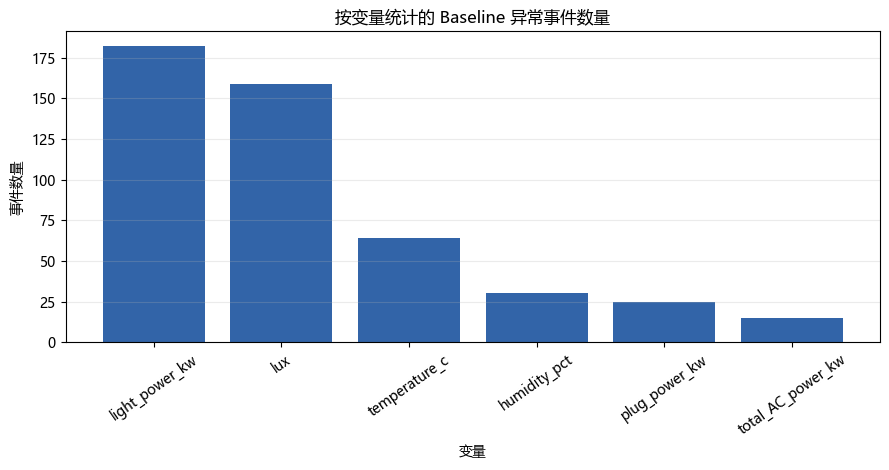

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\02_anomaly_events_by_zone.png


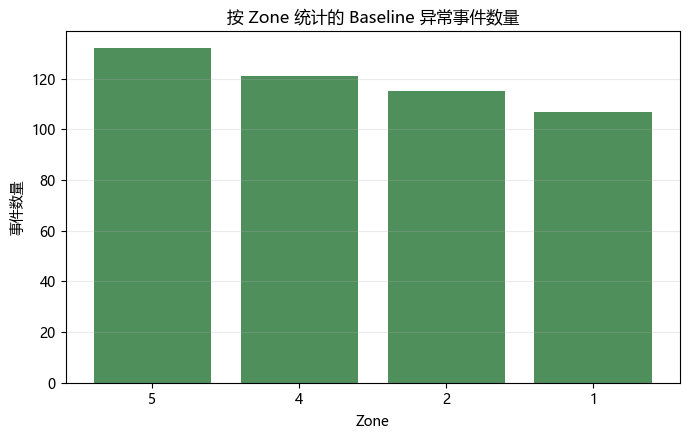

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\03_anomaly_points_by_operating_period.png


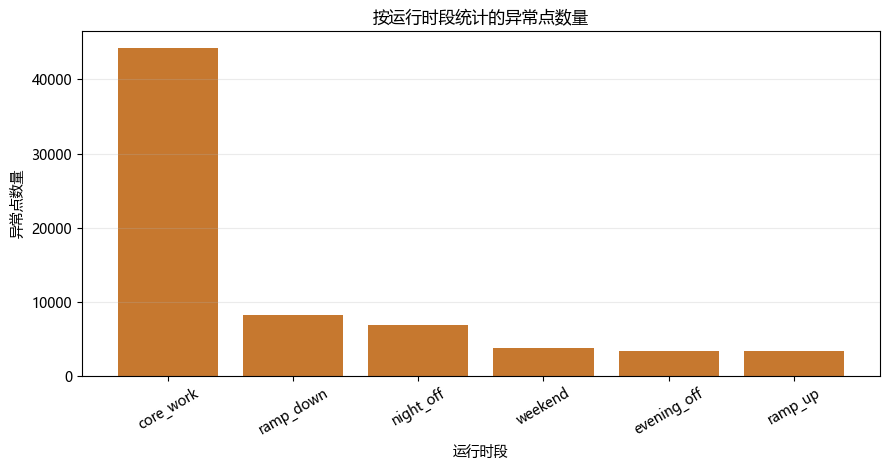

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\04_anomaly_heatmap_variable_hour.png


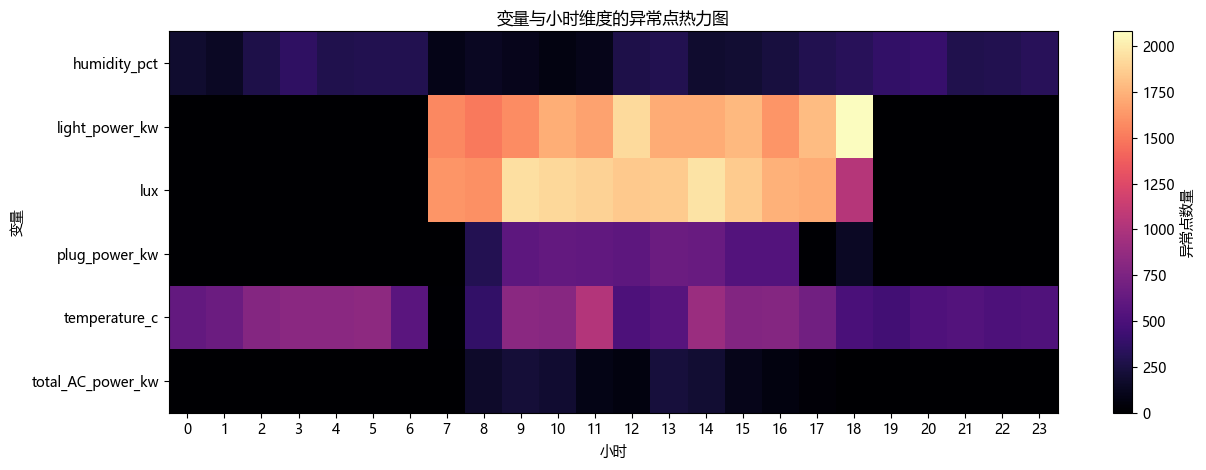

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\05_anomaly_heatmap_variable_operating_period.png


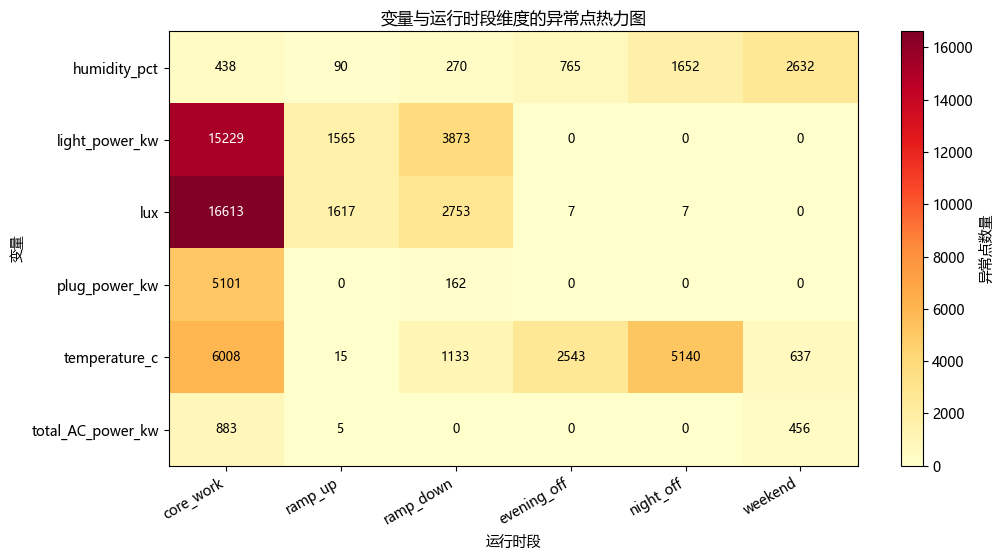

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\06_anomaly_heatmap_zone_operating_period.png


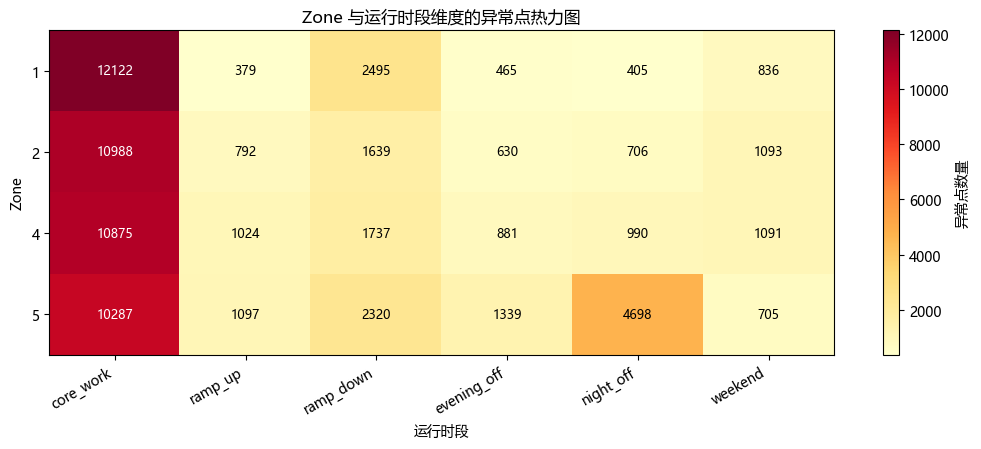

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\07_anomaly_events_by_severity.png


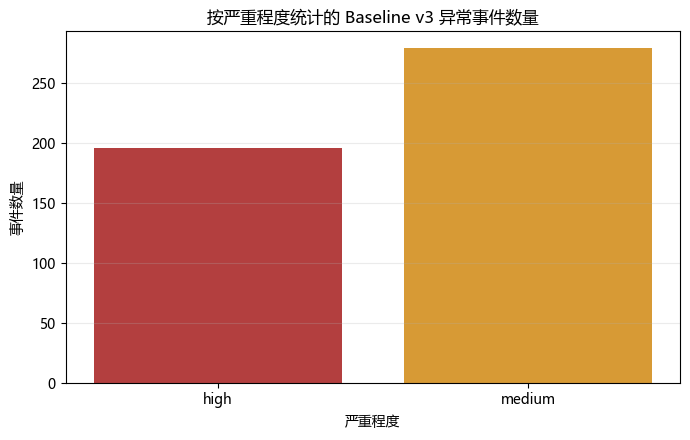

In [41]:

def save_current_figure(file_name: str) -> None:
    path = FIGURE_DIR / file_name
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    safe_print("已保存图表:", path)


def plot_count_heatmap(table: pd.DataFrame, title: str, x_label: str, y_label: str, file_name: str) -> None:
    if table.empty:
        return

    fig_width = max(8, 1.25 * len(table.columns) + 3)
    fig_height = max(4.5, 0.55 * len(table.index) + 2.4)
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    im = ax.imshow(table.values, aspect="auto", cmap="YlOrRd")
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)
    fig.colorbar(im, ax=ax, label="异常点数量")

    max_value = table.values.max() if table.size else 0
    text_color_threshold = max_value * 0.55
    for row_index in range(table.shape[0]):
        for col_index in range(table.shape[1]):
            value = int(table.iat[row_index, col_index])
            color = "white" if value > text_color_threshold else "black"
            ax.text(col_index, row_index, value, ha="center", va="center", color=color, fontsize=9)

    save_current_figure(file_name)
    plt.show()


if not summary_by_variable.empty:
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.bar(summary_by_variable["variable"], summary_by_variable["events"], color="#3264a8")
    ax.set_title("按变量统计的 Baseline 异常事件数量")
    ax.set_xlabel("变量")
    ax.set_ylabel("事件数量")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("01_anomaly_events_by_variable.png")
    plt.show()

if not summary_by_zone.empty:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.bar(summary_by_zone["zone"].astype(str), summary_by_zone["events"], color="#4f8f5b")
    ax.set_title("按 Zone 统计的 Baseline 异常事件数量")
    ax.set_xlabel("Zone")
    ax.set_ylabel("事件数量")
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("02_anomaly_events_by_zone.png")
    plt.show()

if not summary_by_period.empty:
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.bar(summary_by_period["operating_period"], summary_by_period["anomaly_points"], color="#c6782f")
    ax.set_title("按运行时段统计的异常点数量")
    ax.set_xlabel("运行时段")
    ax.set_ylabel("异常点数量")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("03_anomaly_points_by_operating_period.png")
    plt.show()

if not anomaly_points.empty:
    heatmap = anomaly_points.groupby(["variable", "hour"]).size().unstack("hour", fill_value=0)
    fig, ax = plt.subplots(figsize=(13, 4.8))
    im = ax.imshow(heatmap.values, aspect="auto", cmap="magma")
    ax.set_title("变量与小时维度的异常点热力图")
    ax.set_xlabel("小时")
    ax.set_ylabel("变量")
    ax.set_xticks(range(len(heatmap.columns)))
    ax.set_xticklabels(heatmap.columns)
    ax.set_yticks(range(len(heatmap.index)))
    ax.set_yticklabels(heatmap.index)
    fig.colorbar(im, ax=ax, label="异常点数量")
    save_current_figure("04_anomaly_heatmap_variable_hour.png")
    plt.show()

plot_count_heatmap(
    summary_variable_period,
    "变量与运行时段维度的异常点热力图",
    "运行时段",
    "变量",
    "05_anomaly_heatmap_variable_operating_period.png",
)

plot_count_heatmap(
    summary_zone_period,
    "Zone 与运行时段维度的异常点热力图",
    "运行时段",
    "Zone",
    "06_anomaly_heatmap_zone_operating_period.png",
)

if not summary_by_severity.empty:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.bar(summary_by_severity["severity"], summary_by_severity["events"], color=["#b33f3f", "#d79a35", "#6d8fbd"][:len(summary_by_severity)])
    ax.set_title("按严重程度统计的 Baseline v3 异常事件数量")
    ax.set_xlabel("严重程度")
    ax.set_ylabel("事件数量")
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("07_anomaly_events_by_severity.png")
    plt.show()


### 本步骤结果解释

这个 cell 生成 hybrid state-aware baseline 结果的总体可视化，包括按变量、按 zone、按运行时段、按小时分布、变量 × 运行时段热力图、zone × 运行时段热力图，以及 severity 事件数量图。

这些图的解释必须结合当前代码生成的 `anomaly_events` 和各类 summary table。图表只负责展示分布，不单独证明某个事件一定是设备故障；最终解释应回到事件方法、方向、持续时间、运行时段和 severity。


## 13. 代表性异常事件图

本步骤绘制排名最高的异常事件。每张图展示事件窗口前后实际 15 分钟 rolling 值与情境 baseline median 的对比，并用红色点标出当前事件时间段内的最终异常点。


已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\event_001_zone1_light_power_kw.png


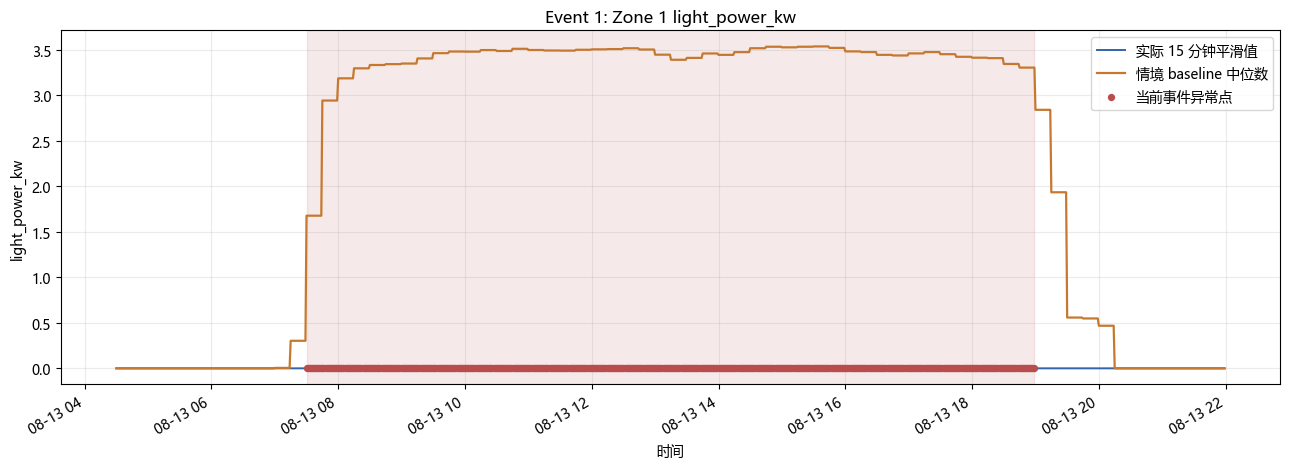

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\event_002_zone1_light_power_kw.png


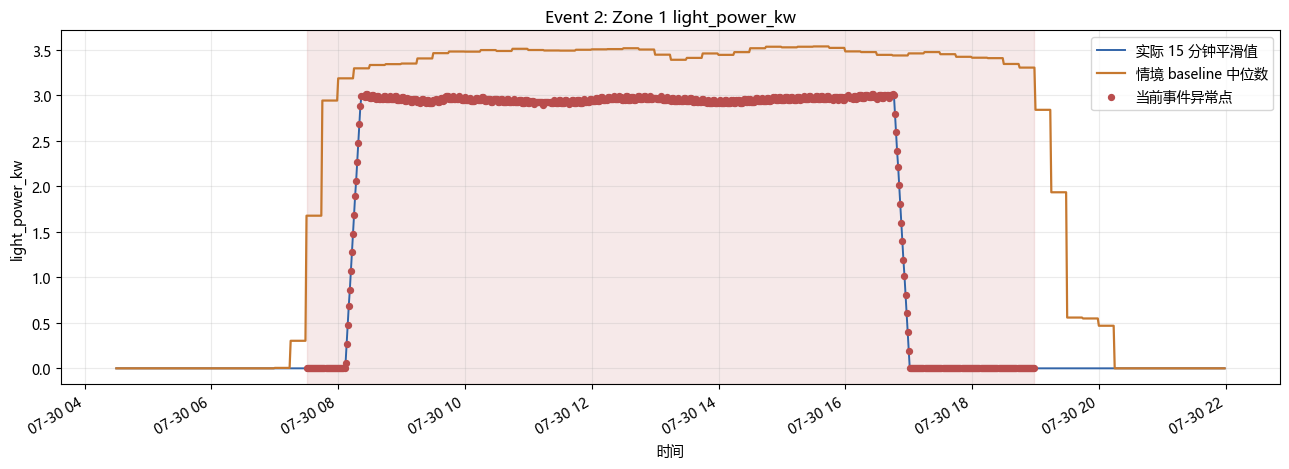

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\event_003_zone5_temperature_c.png


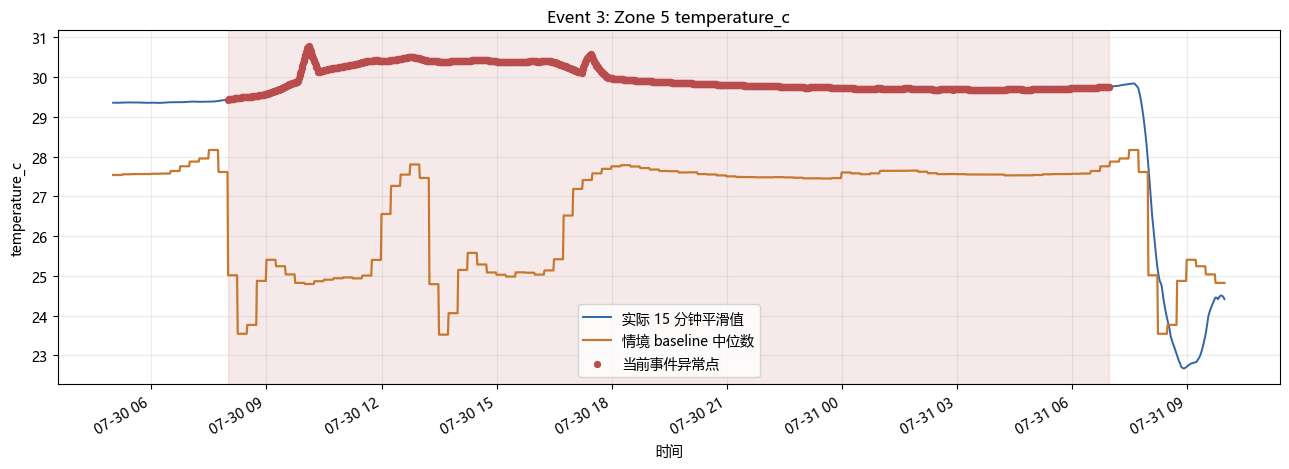

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\event_004_zone2_light_power_kw.png


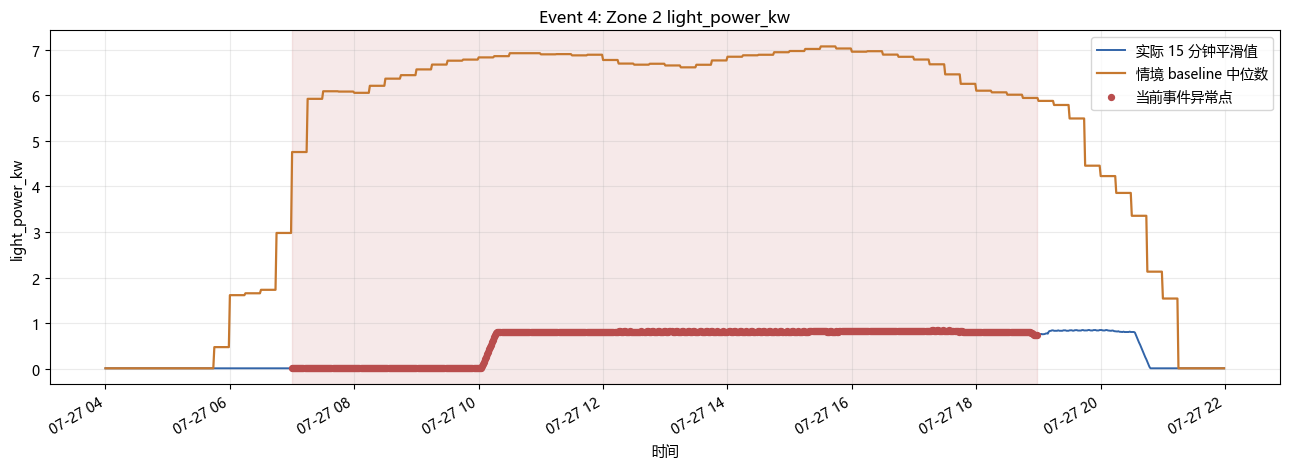

已保存图表: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\event_005_zone5_temperature_c.png


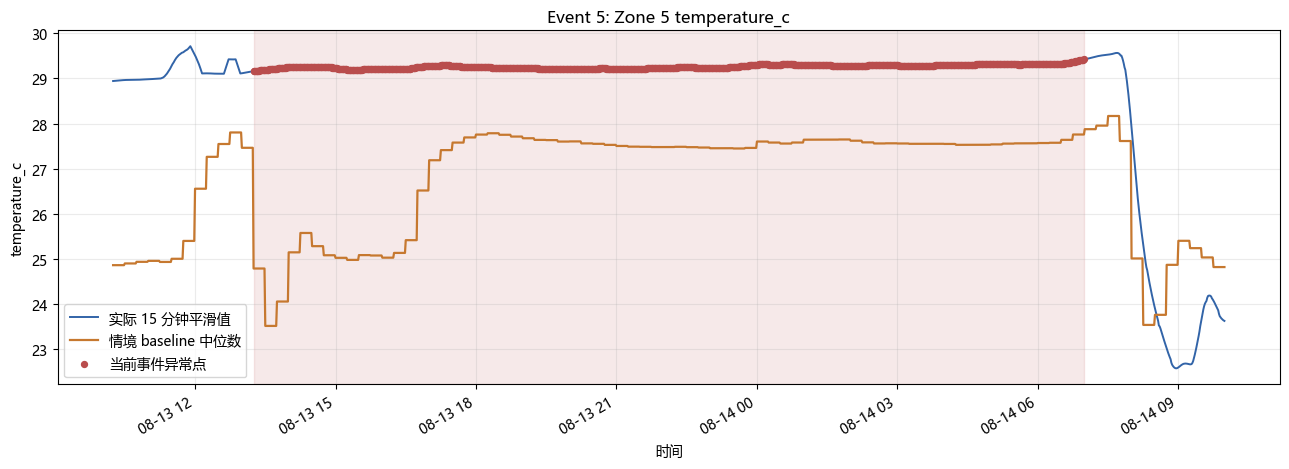

In [42]:
def plot_event(event_row: pd.Series, window_minutes: int = 180) -> None:
    start = pd.to_datetime(event_row["start_time"]) - pd.Timedelta(minutes=window_minutes)
    end = pd.to_datetime(event_row["end_time"]) + pd.Timedelta(minutes=window_minutes)
    subset = scores[
        (scores["zone"] == event_row["zone"])
        & (scores["variable"] == event_row["variable"])
        & (scores["timestamp"].between(start, end))
    ].copy()

    event_start = pd.to_datetime(event_row["start_time"])
    event_end = pd.to_datetime(event_row["end_time"])

    fig, ax = plt.subplots(figsize=(13, 4.8))
    ax.plot(subset["timestamp"], subset["actual_value"], label="实际 15 分钟平滑值", color="#3264a8", linewidth=1.4)
    ax.plot(subset["timestamp"], subset["baseline_median"], label="情境 baseline 中位数", color="#c6782f", linewidth=1.6)
    event_mask = (
        subset["is_anomaly"]
        & subset["timestamp"].between(event_start, event_end)
    )
    ax.scatter(subset.loc[event_mask, "timestamp"], subset.loc[event_mask, "actual_value"], color="#b94d4d", s=18, label="当前事件异常点", zorder=3)
    ax.axvspan(event_start, event_end, color="#b94d4d", alpha=0.12)
    ax.set_title(f"Event {int(event_row['event_id'])}: Zone {event_row['zone']} {event_row['variable']}")
    ax.set_xlabel("时间")
    ax.set_ylabel(event_row["variable"])
    ax.legend()
    ax.grid(True, alpha=0.25)
    fig.autofmt_xdate()
    save_current_figure(f"event_{int(event_row['event_id']):03d}_zone{event_row['zone']}_{event_row['variable']}.png")
    plt.show()


for old_event_figure in FIGURE_DIR.glob("event_*.png"):
    old_event_figure.unlink()

top_events = anomaly_events.head(5).copy()
for _, event in top_events.iterrows():
    plot_event(event)


### 本步骤结果解释

这个 cell 绘制排名最高的 5 个 anomaly events。每张图会显示事件前后窗口中实际 15 分钟平滑值和对应的 contextual baseline median，并用红色点标出当前事件时间段内的最终异常点。

这样做的原因是单纯的分数表不够直观。通过事件图，可以检查异常是否真的明显偏离 baseline，也可以观察异常是突然尖峰、持续升高、持续偏低，还是与某个运行时段转换有关。

这些代表性图适合放入报告中，用来解释 baseline 方法如何发现并呈现异常候选。


## 14. 最终验证

最终验证用于确认所有预期 baseline 输出均已生成，并记录本次统计 baseline 的关键建模设置。


In [43]:
final_validation = pd.DataFrame([{
    "input_dataset": INPUT_DATASET.name,
    "rows_input_wide": len(df),
    "rows_input_long": len(baseline_long),
    "baseline_profile_rows": len(baseline_profile),
    "anomaly_score_rows": len(scores),
    "anomaly_points": int(scores["is_anomaly"].sum()),
    "anomaly_events": len(anomaly_events),
    "robust_z_threshold": ROBUST_Z_THRESHOLD,
    "default_min_persistence_minutes": MIN_PERSISTENCE_MINUTES,
    "period_thresholds": str(PERIOD_ROBUST_Z_THRESHOLDS),
    "dynamic_persistence_rules": "work=30, non_work_energy=30, environment=30",
    "baseline_grouping": " + ".join(BASELINE_GROUP_COLUMNS),
    "operating_periods": ",".join(sorted(df["operating_period"].unique())),
    "table_count": len(list(TABLE_DIR.glob("*.csv"))) + len(list(TABLE_DIR.glob("*.csv.gz"))),
    "figure_count": len(list(FIGURE_DIR.glob("*.png"))),
}])
final_validation.to_csv(TABLE_DIR / "20_final_validation_summary.csv", index=False)

display(final_validation)
safe_print("Baseline 输出目录:", OUTPUT_DIR)
safe_print("Baseline 表格目录:", TABLE_DIR)
safe_print("Baseline 图表目录:", FIGURE_DIR)


,input_dataset,rows_input_wide,rows_input_long,baseline_profile_rows,anomaly_score_rows,anomaly_points,anomaly_events,robust_z_threshold,default_min_persistence_minutes,period_thresholds,dynamic_persistence_rules,baseline_grouping,operating_periods,table_count,figure_count
0,floor6_zone1245_baseline_ready_2018_jul01_sep0...,362880,2177280,4763,2153573,69594,475,3.5,15,"{'core_work': 4.0, 'ramp_up': 4.0, 'ramp_down'...","work=30, non_work_energy=30, environment=30",zone + day_type + fifteen_minute_slot + variab...,"core_work,evening_off,night_off,ramp_down,ramp...",22,12


Baseline 输出目录: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware
Baseline 表格目录: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_tables
Baseline 图表目录: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures


### 本步骤结果解释

最终验证表由当前代码生成，用于确认本 notebook 是否完整产出 hybrid state-aware baseline 所需文件。具体行数、事件数、输出路径和通过状态以 `validation_summary` 的当前输出为准。

验证重点包括：AC baseline 是否包含 `baseline_state`；Transition 是否从 stable AC baseline 中排除；AC、light 和 lux 是否使用分位数主规则；temperature、humidity 和 plug 是否使用 robust-z 主规则；candidate/event 百分比和 ranking score 是否按对应方法计算。

后续报告中应优先解释事件表中的 `anomaly_method`、`anomaly_direction`、`duration_minutes`、`operating_periods`、`max_score_for_ranking` 和 `severity`，而不是只看单个分钟点的 robust-z。
